# SEM basics · 5 — gradients and memory

`PropSEM` is differentiable: give it models that require grad, build a loss from
the record, call `.backward()`, and the gradients come back on the grid. This
notebook does that for an elastic model and then looks at the options that
decide how the backward pass is computed:

1. **Three elastic gradients** — `vp`, `vs` and `rho` from one multi-shot call
2. **Backends and memory strategies** — `impl='c'` / `'eager'` with `Full()`,
   `BoundarySaving()` and `Ckpt(chunks=...)`: time, peak memory, and the gradient
3. **What to use when**

About two minutes on a GPU.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.propagator import Full, BoundarySaving, Ckpt
from sweep.sem import PropSEM
from sweep.sem.equations import ElasticSEM2DDeformed
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## 1. Three elastic gradients

A homogeneous background with three small Gaussian anomalies, one in each
parameter: `vp` on the left, `vs` in the middle, `rho` on the right. The observed
data come from that model; the gradients are taken at the background, with ten
explosive surface shots in one call. All sides absorb, so no surface waves
dominate the data.

In [2]:
dh, n_order, f0, dt, nt = 10.0, 4, 8.0, 0.8e-3, 1500
shape = (97, 193)                                     # 960 m x 1920 m
zz, xx = np.meshgrid(np.arange(shape[0]), np.arange(shape[1]), indexing='ij')
def blob(ix, iz, r=8.0):
    return np.exp(-((xx - ix) ** 2 + (zz - iz) ** 2) / r ** 2).astype(np.float32)

vp0, vs0, rho0 = 2000.0, 1150.0, 2000.0
vp_true  = vp0  * (1 + 0.1 * blob(48, 48))
vs_true  = vs0  * (1 + 0.1 * blob(96, 48))
rho_true = rho0 * (1 + 0.1 * blob(144, 48))
true = [torch.tensor(m, device=device) for m in (vp_true, vs_true, rho_true)]

wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
sx = np.linspace(8, 184, 10).astype(int)
sources = np.stack([sx, np.full_like(sx, 4)], axis=1)            # 10 shots
rx = np.arange(0, shape[1], 2)
receivers = np.stack([rx, np.full_like(rx, 4)], axis=1)[None]    # one spread
impl = 'c' if device == 'cuda' else 'eager'

def make_solver(impl, memory):
    return PropSEM(ElasticSEM2DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                   abcn=20, f_dominant=f0, source_type=['sxx', 'szz'],
                   receiver_type=['vx', 'vz'], impl=impl, memory=memory, device=device)

with torch.no_grad():
    observed = make_solver(impl, Full())(wavelet, sources, receivers, models=true)
print('observed', tuple(observed.shape))

observed (10, 1500, 97, 2)


A unit source gives records of order 1e-12 here, and a loss of their squares is
small enough to underflow in single precision. The wave equation is linear in the
source, so we scale the wavelet once to give records of order one, and the
observed data with it:

In [3]:
scale = 1.0 / float(observed.pow(2).mean().sqrt())
wavelet = wavelet * scale
observed = observed * scale
print('wavelet scale %.2e' % scale)

wavelet scale 1.96e+13


The gradient call: models are leaf tensors with `requires_grad=True`, the loss is
an ordinary PyTorch expression, and `.backward()` fills `.grad`. A model tensor
shared by all shots receives the **sum** of the per-shot gradients, as autograd
gives a tensor reused across a loop.

loss 3.531e+01


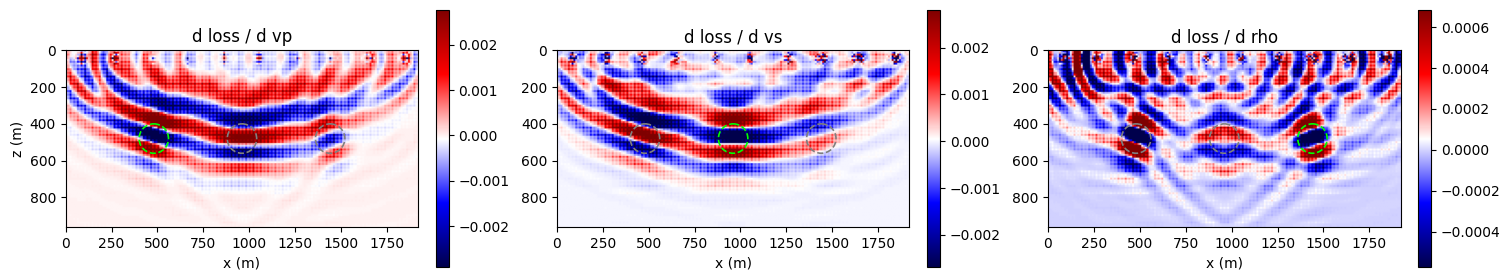

In [4]:
def gradient(solver, src=sources, obs=None):
    obs = observed if obs is None else obs
    models = [torch.full(shape, v, device=device, requires_grad=True)
              for v in (vp0, vs0, rho0)]
    pred = solver(wavelet, src, receivers, models=models)
    loss = 0.5 * (pred - obs).pow(2).sum()
    loss.backward()
    return loss.item(), [m.grad.detach().clone() for m in models]

loss, grads = gradient(make_solver(impl, Full()))
print('loss %.3e' % loss)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.3), constrained_layout=True)
for ax, g, name in zip(axes, grads, ['vp', 'vs', 'rho']):
    g = g.cpu().numpy()
    lo, hi = np.percentile(g[12:][g[12:] != 0], [2, 98])     # below the acquisition rows
    im = ax.imshow(g, cmap='seismic', vmin=lo, vmax=hi,
                   extent=[0, (shape[1] - 1) * dh, (shape[0] - 1) * dh, 0])
    for ix, c in zip((48, 96, 144), ('vp', 'vs', 'rho')):
        ax.add_patch(plt.Circle((ix * dh, 480), 80, fill=False, ls='--',
                                color='lime' if c == name else '0.5', lw=1.2))
    ax.set_title(f'd loss / d {name}'); ax.set_xlabel('x (m)')
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel('z (m)')
plt.show()

These are first update directions, not images: the anomalies show through the
reflections they cause, along the wavepaths between the surface and them. The
`vs` gradient peaks at the `vs` anomaly (green circle), and the `rho` gradient at
the `rho` one, but each also sees the others (grey circles), most clearly `rho`
at the `vp` anomaly: from surface data the three parameters trade off, the
usual multi-parameter cross-talk. The faint dotted texture is the imprint of the
40 m elements: the model reaches the GLL nodes by interpolation, and the
gradient comes back through its transpose. The gradient stops at the model
edge; the absorbing layer reads the edge values of the model but is not part of
it.

## 2. Backends and memory strategies

The backward pass needs the forward wavefield in reverse time order. `memory=`
on the constructor picks how it is kept:

| `memory` | keeps | backward costs |
| --- | --- | --- |
| `Full()` | every time step | nothing extra; memory grows with `nt` |
| `BoundarySaving()` | the C-PML band of every step | one extra step per step: the interior is rebuilt backward in time |
| `Ckpt(chunks=K)` | one state every `K` steps | the chunk is recomputed under autograd |

Without `memory=`, `PropSEM` takes boundary saving on `impl='c'` where the
kernels have it, and `Ckpt(chunks=8)` on eager; `solver.memory_strategy` reports
which. We run each combination on one shot (the middle one), after a warm-up
call (the eager step compiles on first use), and compare time, peak GPU memory
and the `vp` gradient against `impl='c'` with `Full()`.

In [5]:
configs = [('c', Full(), 'Full()'), ('c', Full(), 'Full() again'),
           ('c', BoundarySaving(), 'BoundarySaving()'),
           ('c', None, '(default)'), ('eager', Full(), 'Full()'),
           ('eager', Ckpt(chunks=8), 'Ckpt(chunks=8)'), ('eager', None, '(default)')]
if device != 'cuda':
    configs = [cfg for cfg in configs if cfg[0] == 'eager']

one_src = sources[5:6]                                 # one shot
one_obs = observed[5:6]
rows, ref = [], None
for impl_k, memory, label in configs:
    solver = make_solver(impl_k, memory)
    gradient(solver, one_src, one_obs)                 # warm-up (compiles eager)
    if device == 'cuda':
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    _, g = gradient(solver, one_src, one_obs)
    if device == 'cuda':
        torch.cuda.synchronize()
    sec = time.perf_counter() - t0
    peak = torch.cuda.max_memory_allocated() / 2**20 if device == 'cuda' else float('nan')
    ref = g[0] if ref is None else ref
    rel = float((g[0] - ref).norm() / ref.norm())
    rows.append((impl_k, label, solver.memory_strategy, sec, peak, rel))

print(f"{'impl':6s} {'memory':17s} {'strategy':9s} {'fwd+bwd (s)':>11s} {'peak (MB)':>10s} {'vp grad vs first row':>21s}")
for r in rows:
    print(f'{r[0]:6s} {r[1]:17s} {r[2]:9s} {r[3]:11.2f} {r[4]:10.0f} {r[5]:21.1e}')

sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 97x193 grid (with gradients); the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 97x193 grid


sweep: torch.compile is compiling the ElasticSEM2DDeformed step for a 97x193 grid (with gradients)


impl   memory            strategy  fwd+bwd (s)  peak (MB)  vp grad vs first row
c      Full()            full             0.11       2111               0.0e+00
c      Full() again      full             0.11       2111               8.9e-04
c      BoundarySaving()  boundary         0.22        920               1.4e-03
c      (default)         boundary         0.22        920               2.7e-03
eager  Full()            full             3.39       4382               2.5e-03
eager  Ckpt(chunks=8)    ckpt             0.40        616               3.5e-03
eager  (default)         ckpt             0.40        616               2.5e-03


Reading the table (a 97 x 193 grid, 1500 steps, three shots):

- all give the same gradient to within a few parts in a thousand, which is the
  run-to-run spread of the single-precision backward itself (the `impl='c'`
  backward accumulates with atomics, so two identical runs differ too): the
  memory strategy changes what is stored, not what is computed;
- **boundary saving** keeps only the C-PML band, at the cost of rebuilding the
  interior backward in time. Its saving grows with the model: here the band is
  a large part of the small mesh, on a production model it is a thin rim;
- on **eager**, `Full()` keeps an autograd tape of every step and is both the
  slowest and the most memory-hungry; the default `Ckpt(chunks=8)` replays each
  chunk as a CUDA graph and is several times faster at a fraction of the memory.
  It is the way to run the equations that have no CUDA kernels.

## 3. What to use when

- **Many shots, an equation with `impl='c'`**: the defaults (`impl=None` on a GPU,
  no `memory=`) — CUDA kernels with boundary saving, and all shots of a call in
  one batched kernel sequence.
- **An equation without CUDA kernels, or the CPU**: eager with its default
  `Ckpt(chunks=8)`.
- **Second derivatives** (`create_graph=True`, Hessian-vector products): eager
  with `Full()`; the other strategies refuse it.
- **Biot**: `Full()` or `Ckpt`; boundary saving is refused because the viscous
  drag cannot be stepped backward.
- **Per-shot models** — `models=[vp_b]` with `vp_b` of shape `(nshots, nz, nx)`
  gives each shot its own model and keeps the gradients per shot; see
  [Batched local windows · FWI](../44_sem_batched_local_window_fwi/).

Next: [SEM basics · 6 — water over an elastic sea floor](../55_sem_fluid_solid/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="54_sem_gradients_and_memory.ipynb" download><code>54_sem_gradients_and_memory.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/54_sem_gradients_and_memory.ipynb">view on GitHub</a></p>